# Actividad 6 – Evaluación y validación de un modelo de churn de Sierra Móvil

**Problema:** clasificación binaria. Predecir si un cliente se da de baja (`Churn = 1`) para decidir a quién contactar con una oferta de retención.

**Objetivo SMART.** Seleccionar y validar un clasificador de churn con umbral de decisión basado en costos, de modo que
1. ROC-AUC ≥ 0.80 en validación cruzada y en prueba
2. el beneficio neto esperado por cliente supere al de un umbral de 0.5 y al de las líneas base
3. diferencia contra la estrategia actual sea significativa (p < 0.05, prueba Z de dos proporciones) probar en un A/B
4. registrar en MLflow


## 1. Configuración, supuestos de la Fase I y datos

In [1]:
# carga las librerías
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             roc_curve)
from sklearn.model_selection import (RepeatedStratifiedKFold, StratifiedKFold,
                                     cross_val_predict, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .25, "font.size": 10})
C_LR, C_RF, C_BASE, C_GRIS, C_ALT = "#1f6f8b", "#e07a1f", "#8a8f98", "#c9ccd1", "#2a9d8f"

RAIZ = Path.cwd()
if RAIZ.name == "fuentes":
    RAIZ = RAIZ.parent
EVID = RAIZ / "evidencias" / "act6"; GRAF = EVID / "graficas"
GRAF.mkdir(parents=True, exist_ok=True)

SEMILLA = 42

# define los costos de la Fase I ($46 de contacto, $1,440 por cliente retenido, etc) 
# calcula el umbral teórico

# --- Supuestos tomados de 'PIA - Sierra Movil ROI v2.xlsx' (hoja Supuestos) ---
CLIENTES               = 400_000
CAPACIDAD              = 0.15      # % de la base que Comercial puede contactar
COSTO_CONTACTO         = 46        # MXN por cliente contactado (C_FP)
ARPU, MARGEN, MESES    = 300, 0.40, 12
ACEPTACION, ATRIBUCION = 0.20, 0.85

VALOR_CLIENTE   = ARPU * MARGEN * MESES                             # 1,440 MXN
EFECTO          = ACEPTACION * ATRIBUCION                           # 0.17 prob. de retener a un cliente que sí se iba
BENEFICIO_VP    = VALOR_CLIENTE * EFECTO                            # 244.80 (= C_FN: oportunidad perdida)
NETO_VP         = BENEFICIO_VP - COSTO_CONTACTO                     # 198.80
UMBRAL_TEORICO  = COSTO_CONTACTO / BENEFICIO_VP                     # 0.188
UMBRAL_CURSO    = COSTO_CONTACTO / (COSTO_CONTACTO + BENEFICIO_VP)  # 0.158 (formula sin costo de VP)

print(f"Valor por cliente retenido: {VALOR_CLIENTE:,.0f} MXN")
print(f"Beneficio esperado por VP (C_FN): {BENEFICIO_VP:,.2f} MXN | neto por VP: {NETO_VP:,.2f} MXN")
print(f"Umbral teórico (matriz de costos completa): {UMBRAL_TEORICO:.3f}")
print(f"Umbral con la fórmula simplificada: {UMBRAL_CURSO:.3f}")

Valor por cliente retenido: 1,440 MXN
Beneficio esperado por VP (C_FN): 244.80 MXN | neto por VP: 198.80 MXN
Umbral teórico (matriz de costos completa): 0.188
Umbral con la fórmula simplificada: 0.158


In [2]:
# lee los datos y los divide en entrenamiento (80 %) y prueba (20 %) 
# Entrena los modelos y calcula las dos líneas base

df = pd.read_csv(RAIZ / "datos" / "datos_limp" / "telco_churn_limpio.csv")
X = df.drop(columns=["customerID", "Churn"]); y = df["Churn"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y,
                                          random_state=SEMILLA)
print(f"Clientes: {len(df):,} | churn: {y.mean():.1%} | train: {len(X_tr):,} | test: {len(X_te):,}")

NUM = ["tenure", "MonthlyCharges", "TotalCharges"]
CAT = [c for c in X.columns if c not in NUM]

def crear_pipeline(clf):
    prep = ColumnTransformer([("num", StandardScaler(), NUM), ("cat", OneHotEncoder(handle_unknown="ignore"), CAT)])
    return Pipeline([("prep", prep), ("clf", clf)])

# Hiperparámetros: mejores resultados del Grid Search de la Actividad 5 (AUC, 5-fold)
def modelo_lr(): 
    return crear_pipeline(LogisticRegression(C=10, max_iter=1000, random_state=SEMILLA))

def modelo_rf(): 
    return crear_pipeline(RandomForestClassifier(n_estimators=200, max_depth=5,min_samples_leaf=5, random_state=SEMILLA))

lr = modelo_lr().fit(X_tr, y_tr)
rf = modelo_rf().fit(X_tr, y_tr)
p_lr = lr.predict_proba(X_te)[:, 1]
p_rf = rf.predict_proba(X_te)[:, 1]

# Línea base 1: clasificador que ignora los datos (siempre la clase mayoritaria)
dummy = DummyClassifier(strategy="prior").fit(X_tr, y_tr)
p_dummy = dummy.predict_proba(X_te)[:, 1]

# Línea base 2: regla de negocio actual -> contactar contratos mes a mes
regla_te = (X_te["Contract"] == "Month-to-month").astype(int).to_numpy()
print(f"Regla de negocio (mes a mes): {regla_te.mean():.1%} de la base de prueba, churn dentro de la regla {y_te[regla_te == 1].mean():.1%}")

Clientes: 7,043 | churn: 26.5% | train: 5,634 | test: 1,409
Regla de negocio (mes a mes): 54.9% de la base de prueba, churn dentro de la regla 42.6%


## 2. Matriz de confusión y métricas (umbral estándar 0.5)

- Se evalúa en el `conjunto de prueba` que no se usó para entrenar ni para ajustar hiperparámetros
- Convención: positivo = `Churn = 1` (cliente que se va).

In [3]:
def metricas(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"VP": tp, "FP": fp, "FN": fn, "VN": tn,
            "Exactitud": (tp + tn) / (tp + tn + fp + fn),
            "Precisión": tp / (tp + fp) if tp + fp else 0.0,
            "Recall": tp / (tp + fn),
            "Especificidad": tn / (tn + fp),
            "F1": 2 * tp / (2 * tp + fp + fn)}

m_lr05 = metricas(y_te, p_lr >= 0.5)
m_rf05 = metricas(y_te, p_rf >= 0.5)
m_regla = metricas(y_te, regla_te)
tabla_05 = pd.DataFrame({"Regresión logística": m_lr05, "Random forest": m_rf05, "Regla mes a mes": m_regla}).T
assert all(int(tabla_05.loc[i, ["VP", "FP", "FN", "VN"]].sum()) == len(y_te) for i in tabla_05.index)
print("Verificación VP+FP+FN+VN = N =", len(y_te))
display(tabla_05.round(4))

Verificación VP+FP+FN+VN = N = 1409


,VP,FP,FN,VN,Exactitud,Precisión,Recall,Especificidad,F1
Regresión logística,209.0,108.0,165.0,927.0,0.8062,0.6593,0.5588,0.8957,0.6049
Random forest,155.0,75.0,219.0,960.0,0.7913,0.6739,0.4144,0.9275,0.5132
Regla mes a mes,329.0,444.0,45.0,591.0,0.6529,0.4256,0.8797,0.5710,0.5737


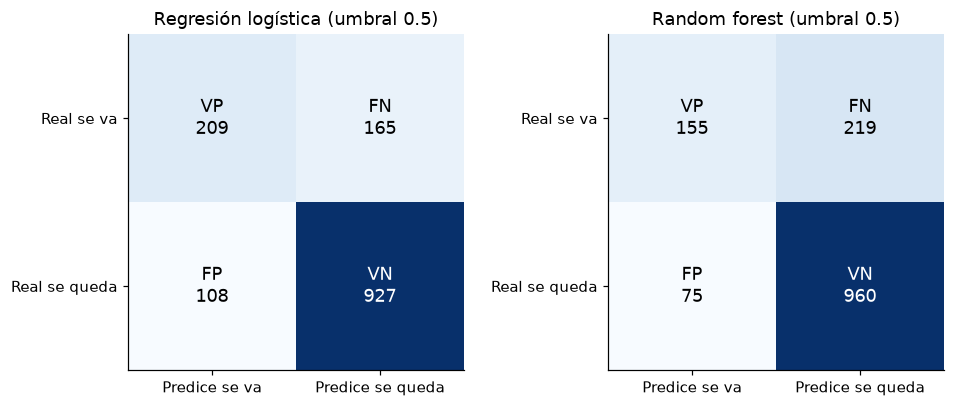

In [4]:
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, m, tit in zip(axs, [m_lr05, m_rf05], ["Regresión logística", "Random forest"]):
    cm = np.array([[m["VP"], m["FN"]], [m["FP"], m["VN"]]])
    ax.imshow(cm, cmap="Blues"); ax.grid(False)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{['VP','FN','FP','VN'][2*i+j]}\n{cm[i,j]}", ha="center", va="center",
                    color="white" if cm[i, j] > cm.max()/2 else "black", fontsize=12)
    ax.set_xticks([0, 1], ["Predice se va", "Predice se queda"])
    ax.set_yticks([0, 1], ["Real se va", "Real se queda"])
    ax.set_title(f"{tit} (umbral 0.5)")

fig.tight_layout()
fig.savefig(GRAF / "01_matrices_confusion.png", dpi=160)
plt.show()

## 3. Curva ROC y AUC

La curva ROC muestra TPR (recall) frente a FPR para **todos** los umbrales posibles. El AUC resume la capacidad de ordenar a los clientes que se van por encima de los que se quedan. Se agrega un intervalo de confianza por *bootstrap* (1,000 remuestreos del conjunto de prueba).

In [5]:
def auc_ic(y_true, score, n_boot=1000, seed=SEMILLA):
    rng = np.random.default_rng(seed); y_true = np.asarray(y_true); n = len(y_true); vals = []
    for _ in range(n_boot):
        i = rng.integers(0, n, n)
        if y_true[i].min() == y_true[i].max():
            continue

        vals.append(roc_auc_score(y_true[i], score[i]))
        
    return roc_auc_score(y_true, score), np.percentile(vals, [2.5, 97.5])

auc = {}
for nom, sc in [("Regresión logística", p_lr), ("Random forest", p_rf),
                ("Regla mes a mes", regla_te.astype(float)), ("Dummy (prior)", p_dummy)]:
    a, ic = auc_ic(y_te, sc); auc[nom] = (a, ic[0], ic[1])
tabla_auc = pd.DataFrame(auc, index=["AUC", "IC95 inf", "IC95 sup"]).T
display(tabla_auc.round(4))

,AUC,IC95 inf,IC95 sup
Regresión logística,0.8415,0.8186,0.8621
Random forest,0.8429,0.8204,0.8645
Regla mes a mes,0.7253,0.7022,0.7468
Dummy (prior),0.5000,0.5000,0.5000


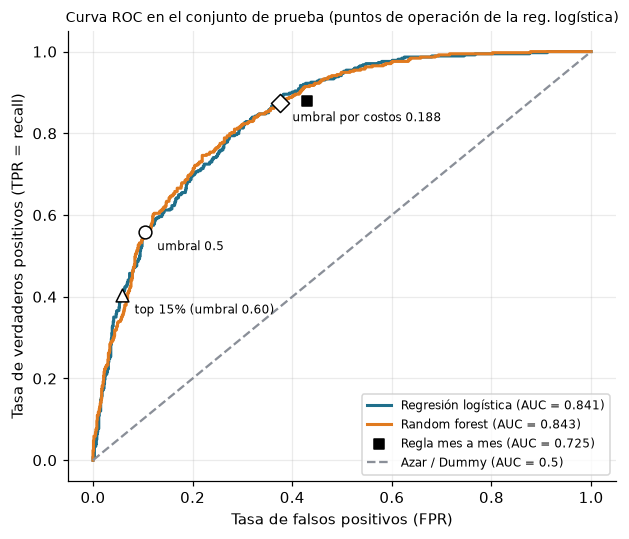

In [6]:
umbral_top15 = float(np.quantile(p_lr, 1 - CAPACIDAD))   # umbral que deja al 15% de mayor riesgo
fig, ax = plt.subplots(figsize=(5.8, 5))
for nom, sc, col in [("Regresión logística", p_lr, C_LR), ("Random forest", p_rf, C_RF)]:
    f, t, _ = roc_curve(y_te, sc)
    ax.plot(f, t, color=col, lw=2, label=f"{nom} (AUC = {auc[nom][0]:.3f})")
f_r, t_r = m_regla["FP"]/(m_regla["FP"]+m_regla["VN"]), m_regla["Recall"]
ax.scatter([f_r], [t_r], color="black", marker="s", zorder=5, label=f"Regla mes a mes (AUC = {auc['Regla mes a mes'][0]:.3f})")
ax.plot([0, 1], [0, 1], "--", color=C_BASE, label="Azar / Dummy (AUC = 0.5)")
for t_op, etq, mk in [(0.5, "umbral 0.5", "o"), (UMBRAL_TEORICO, f"umbral por costos {UMBRAL_TEORICO:.3f}", "D"),
                      (umbral_top15, f"top 15% (umbral {umbral_top15:.2f})", "^")]:
    mm = metricas(y_te, p_lr >= t_op)
    ax.scatter([mm["FP"]/(mm["FP"]+mm["VN"])], [mm["Recall"]], s=70, marker=mk, edgecolor="black", color="white", zorder=6)
    ax.annotate(etq, (mm["FP"]/(mm["FP"]+mm["VN"]), mm["Recall"]), textcoords="offset points", xytext=(8, -12), fontsize=8)
ax.set_xlabel("Tasa de falsos positivos (FPR)"); ax.set_ylabel("Tasa de verdaderos positivos (TPR = recall)")
ax.set_title("Curva ROC en el conjunto de prueba (puntos de operación de la reg. logística)")
ax.title.set_fontsize(9); ax.legend(loc="lower right", fontsize=8)
fig.tight_layout(); fig.savefig(GRAF / "02_curva_roc.png", dpi=160); plt.show()

## 4. Ajuste de umbral basado en costos

**Importante (evitar fuga de información):** el umbral se elige con predicciones **fuera de muestra del conjunto de entrenamiento** (`cross_val_predict`, 5 folds). El conjunto de prueba se usa **una sola vez**, al final, para reportar.

Matriz de costos (Fase I)
- contactar cuesta 46 MXN siempre
- un VP además recupera 244.80 MXN esperados
- un FN pierde esa oportunidad
- Beneficio neto por cliente = (VP × 198.80 − FP × 46) / N
- Fórmula simplificada: Costo = FP × C_FP + FN × C_FN
    - con C_FP = 46 y C_FN = 244.80

In [7]:
cv5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
oof_lr = cross_val_predict(modelo_lr(), X_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
oof_rf = cross_val_predict(modelo_rf(), X_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
print(f"AUC fuera de muestra (train): LR {roc_auc_score(y_tr, oof_lr):.4f} | RF {roc_auc_score(y_tr, oof_rf):.4f}")

def neto_por_cliente(y_true, pred):
    y_true = np.asarray(y_true); pred = np.asarray(pred).astype(bool)
    vp = (pred & (y_true == 1)).sum(); fp = (pred & (y_true == 0)).sum()
    return (vp * NETO_VP - fp * COSTO_CONTACTO) / len(y_true)

def costo_curso(y_true, pred):
    y_true = np.asarray(y_true); pred = np.asarray(pred).astype(bool)
    fp = (pred & (y_true == 0)).sum(); fn = (~pred & (y_true == 1)).sum()
    return (fp * COSTO_CONTACTO + fn * BENEFICIO_VP) / len(y_true)

umbrales = np.round(np.arange(0.05, 0.86, 0.01), 2)
def barrido(y_true, score):
    filas = []
    for t in umbrales:
        pr = score >= t; m = metricas(y_true, pr)
        filas.append({"umbral": t, "marcados": pr.mean(), "precision": m["Precisión"], "recall": m["Recall"],
                      "f1": m["F1"], "neto_cliente": neto_por_cliente(y_true, pr), "costo_curso": costo_curso(y_true, pr)})
    return pd.DataFrame(filas)

bar_lr, bar_rf = barrido(y_tr, oof_lr), barrido(y_tr, oof_rf)
t_f1 = float(bar_lr.loc[bar_lr.f1.idxmax(), "umbral"])
t_neto = float(bar_lr.loc[bar_lr.neto_cliente.idxmax(), "umbral"])
t_curso = float(bar_lr.loc[bar_lr.costo_curso.idxmin(), "umbral"])
print(f"Umbral óptimo por F1: {t_f1} | por beneficio neto (empírico): {t_neto} | por fórmula: {t_curso}")
print(f"Umbral teórico por costos: {UMBRAL_TEORICO:.3f} (coincide con el empírico: la curva es plana entre 0.15 y 0.30)")
bar_lr.to_csv(EVID / "barrido_umbral_lr_oof.csv", index=False)

AUC fuera de muestra (train): LR 0.8459 | RF 0.8461
Umbral óptimo por F1: 0.31 | por beneficio neto (empírico): 0.17 | por fórmula: 0.17
Umbral teórico por costos: 0.188 (coincide con el empírico: la curva es plana entre 0.15 y 0.30)


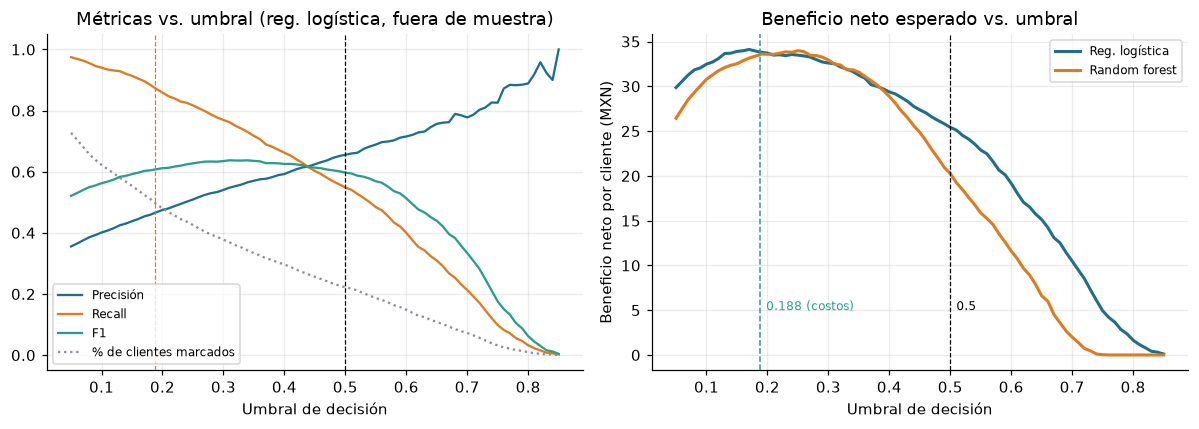

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ax = axs[0]
ax.plot(bar_lr.umbral, bar_lr.precision, color=C_LR, label="Precisión")
ax.plot(bar_lr.umbral, bar_lr.recall, color=C_RF, label="Recall")
ax.plot(bar_lr.umbral, bar_lr.f1, color=C_ALT, label="F1")
ax.plot(bar_lr.umbral, bar_lr.marcados, color=C_BASE, ls=":", label="% de clientes marcados")
ax.axvline(0.5, color="black", ls="--", lw=.8); ax.axvline(UMBRAL_TEORICO, color=C_RF, ls="--", lw=.8)
ax.set_xlabel("Umbral de decisión"); ax.set_title("Métricas vs. umbral (reg. logística, fuera de muestra)")
ax.legend(fontsize=8)
ax = axs[1]
ax.plot(bar_lr.umbral, bar_lr.neto_cliente, color=C_LR, lw=2, label="Reg. logística")
ax.plot(bar_rf.umbral, bar_rf.neto_cliente, color=C_RF, lw=2, label="Random forest")
ax.axvline(0.5, color="black", ls="--", lw=.8); ax.text(0.51, 5, "0.5", fontsize=8)
ax.axvline(UMBRAL_TEORICO, color=C_ALT, ls="--", lw=1); ax.text(UMBRAL_TEORICO+.01, 5, f"{UMBRAL_TEORICO:.3f} (costos)", fontsize=8, color=C_ALT)
ax.set_xlabel("Umbral de decisión"); ax.set_ylabel("Beneficio neto por cliente (MXN)")
ax.set_title("Beneficio neto esperado vs. umbral"); ax.legend(fontsize=8)
fig.tight_layout(); fig.savefig(GRAF / "03_ajuste_umbral.png", dpi=160); plt.show()

In [9]:
# Evaluación ÚNICA en prueba de los umbrales candidatos (elegidos sin usar prueba)
candidatos = {"0.5 (estándar)": 0.5, f"Máx. F1 ({t_f1})": t_f1,
              f"Costos teórico ({UMBRAL_TEORICO:.3f})": UMBRAL_TEORICO,
              f"Fórmula curso ({UMBRAL_CURSO:.3f})": UMBRAL_CURSO,
              f"Top 15% (capacidad, {umbral_top15:.2f})": umbral_top15}
filas = []
for nom, t in candidatos.items():
    pr = p_lr >= t; m = metricas(y_te, pr); neto = neto_por_cliente(y_te, pr)
    filas.append({"Umbral": nom, "% marcados": pr.mean(), "VP": m["VP"], "FP": m["FP"], "FN": m["FN"],
                  "Precisión": m["Precisión"], "Recall": m["Recall"], "F1": m["F1"],
                  "Neto/cliente (MXN)": neto, "Neto anual proyectado (MDP)": neto * CLIENTES / 1e6})
# Referencias de negocio sin modelo
pr_todos = np.ones(len(y_te), bool); pr_regla = regla_te.astype(bool)
for nom, pr in [("Contactar a todos", pr_todos), ("Regla mes a mes (todos)", pr_regla)]:
    m = metricas(y_te, pr); neto = neto_por_cliente(y_te, pr)
    filas.append({"Umbral": nom, "% marcados": pr.mean(), "VP": m["VP"], "FP": m["FP"], "FN": m["FN"],
                  "Precisión": m["Precisión"], "Recall": m["Recall"], "F1": m["F1"],
                  "Neto/cliente (MXN)": neto, "Neto anual proyectado (MDP)": neto * CLIENTES / 1e6})
tabla_umbral = pd.DataFrame(filas).set_index("Umbral")
tabla_umbral.to_csv(EVID / "comparacion_umbrales_test.csv")
display(tabla_umbral.round(3))
print("Nota: el neto anual proyectado es bruto, antes de los costos del proyecto (inversión y operación) de la Fase I.")

,% marcados,VP,FP,FN,Precisión,Recall,F1,Neto/cliente (MXN),Neto anual proyectado (MDP)
Umbral,,,,,,,,,
0.5 (estándar),0.225,209,108,165,0.659,0.559,0.605,25.963,10.385
Máx. F1 (0.31),0.375,277,252,97,0.524,0.741,0.614,30.856,12.342
Costos teórico (0.188),0.508,327,389,47,0.457,0.874,0.600,33.438,13.375
Fórmula curso (0.158),0.541,338,424,36,0.444,0.904,0.595,33.847,13.539
"Top 15% (capacidad, 0.60)",0.150,151,61,223,0.712,0.404,0.515,19.314,7.725
Contactar a todos,1.000,374,1035,0,0.265,1.000,0.420,18.979,7.592
Regla mes a mes (todos),0.549,329,444,45,0.426,0.880,0.574,31.924,12.770


Nota: el neto anual proyectado es bruto, antes de los costos del proyecto (inversión y operación) de la Fase I.


## 5. Validación cruzada, comparación con baseline y significancia estadística

- Validación cruzada **estratificada 5-fold × 3 repeticiones** (15 puntajes por modelo) sobre el conjunto de entrenamiento
- En cada fold se reentrena el modelo completo (escalado y *one-hot* dentro del `Pipeline`)
- El umbral de decisión es el **teórico por costos (0.188)**, derivado de los costos y no de los datos, por lo que no hay fuga de información.

Estrategias comparadas
- regresión logística
- random forest
- regla de negocio (contrato mes a mes)
- contactar a todos
- Dummy (no contactar a nadie AUC = 0.5)

In [10]:
rcv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEMILLA)
reg = []
for k, (i_tr, i_va) in enumerate(rcv.split(X_tr, y_tr)):
    Xa, Xb, ya, yb = X_tr.iloc[i_tr], X_tr.iloc[i_va], y_tr.iloc[i_tr], y_tr.iloc[i_va]
    for nom, fab in [("Regresión logística", modelo_lr), ("Random forest", modelo_rf)]:
        sc = fab().fit(Xa, ya).predict_proba(Xb)[:, 1]
        for u in ("0.5", "costos"):
            t = 0.5 if u == "0.5" else UMBRAL_TEORICO
            pr = sc >= t; m = metricas(yb, pr)
            reg.append({"fold": k, "modelo": nom, "umbral": u, "auc": roc_auc_score(yb, sc),
                        "precision": m["Precisión"], "recall": m["Recall"], "f1": m["F1"],
                        "neto": neto_por_cliente(yb, pr)})
    regla_v = (Xb["Contract"] == "Month-to-month").to_numpy()
    for nom, pr, a in [("Regla mes a mes", regla_v, 0.5), ("Contactar a todos", np.ones(len(yb), bool), 0.5),
                       ("Dummy (no contactar)", np.zeros(len(yb), bool), 0.5)]:
        m = metricas(yb, pr)
        reg.append({"fold": k, "modelo": nom, "umbral": "costos", "auc": roc_auc_score(yb, regla_v) if nom.startswith("Regla") else 0.5,
                    "precision": m["Precisión"], "recall": m["Recall"], "f1": m["F1"], "neto": neto_por_cliente(yb, pr)})
cv_df = pd.DataFrame(reg); cv_df.to_csv(EVID / "cv_resultados_por_fold.csv", index=False)

def resumen(d, col):
    g = d.groupby("modelo")[col]; n = g.count()
    m, s = g.mean(), g.std(ddof=1); h = stats.t.ppf(.975, n - 1) * s / np.sqrt(n)
    return pd.DataFrame({"media": m, "desv": s, "IC95 inf": m - h, "IC95 sup": m + h})

cv_costos = cv_df[cv_df.umbral == "costos"]
res_auc = resumen(cv_costos[cv_costos.modelo.isin(["Regresión logística", "Random forest", "Regla mes a mes", "Dummy (no contactar)"])], "auc")
res_neto = resumen(cv_costos, "neto"); res_rec = resumen(cv_costos, "recall"); res_f1 = resumen(cv_costos, "f1")
res_cv = pd.concat({"AUC": res_auc["media"], "AUC desv": res_auc["desv"], "Recall": res_rec["media"], "F1": res_f1["media"],
                    "Neto/cliente": res_neto["media"], "Neto desv": res_neto["desv"],
                    "Neto IC95 inf": res_neto["IC95 inf"], "Neto IC95 sup": res_neto["IC95 sup"]}, axis=1)
res_cv.to_csv(EVID / "cv_resumen.csv"); display(res_cv.round(4))

,AUC,AUC desv,Recall,F1,Neto/cliente,Neto desv,Neto IC95 inf,Neto IC95 sup
modelo,,,,,,,,
Dummy (no contactar),0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Random forest,0.8471,0.0119,0.9086,0.5867,33.4211,0.9955,32.8698,33.9724
Regla mes a mes,0.7289,0.0110,0.8870,0.5769,32.2883,1.0038,31.7324,32.8442
Regresión logística,0.8464,0.0120,0.8756,0.6078,33.9149,1.3175,33.1853,34.6445
Contactar a todos,NaN,NaN,1.0000,0.4194,18.9585,0.0239,18.9452,18.9717


In [11]:
def t_corregida(a, b, n_test_sobre_train=0.25):
    # Prueba t pareada con corrección de Nadeau-Bengio para validación cruzada repetida
    d = np.asarray(a) - np.asarray(b); n = len(d)
    var = d.var(ddof=1)
    if var == 0: return 0.0, 1.0, d.mean()
    t = d.mean() / np.sqrt((1 / n + n_test_sobre_train) * var)
    return t, 2 * stats.t.sf(abs(t), n - 1), d.mean()

def serie(nom, col, umbral="costos"):
    d = cv_df[(cv_df.modelo == nom) & (cv_df.umbral == umbral)].sort_values("fold")
    return d[col].to_numpy()

pruebas = []
for a, b, col, umb in [("Regresión logística", "Random forest", "auc", "costos"),
                       ("Regresión logística", "Random forest", "neto", "costos"),
                       ("Regresión logística", "Regla mes a mes", "neto", "costos"),
                       ("Regresión logística", "Contactar a todos", "neto", "costos"),
                       ("Regresión logística", "Dummy (no contactar)", "auc", "costos")]:
    sa, sb = serie(a, col, umb), serie(b, col, umb)
    t, p, dm = t_corregida(sa, sb)
    try: pw = stats.wilcoxon(sa, sb).pvalue
    except ValueError: pw = np.nan
    pruebas.append({"Comparación": f"{a} vs {b}", "Métrica": col, "Dif. media": dm, "t corregida (N-B)": t,
                    "p (N-B)": p, "p (Wilcoxon)": pw, "¿Significativa (α=0.05)?": "Sí" if p < .05 else "No"})
tabla_pruebas = pd.DataFrame(pruebas); tabla_pruebas.to_csv(EVID / "cv_pruebas_significancia.csv", index=False)
display(tabla_pruebas.round(4))

# Sobreajuste: AUC en entrenamiento vs validación cruzada vs prueba
sobre = pd.DataFrame({
    "AUC entrenamiento": [roc_auc_score(y_tr, lr.predict_proba(X_tr)[:, 1]), roc_auc_score(y_tr, rf.predict_proba(X_tr)[:, 1])],
    "AUC validación cruzada": [res_auc.loc["Regresión logística", "media"], res_auc.loc["Random forest", "media"]],
    "AUC prueba": [auc["Regresión logística"][0], auc["Random forest"][0]]},
    index=["Regresión logística", "Random forest"])
display(sobre.round(4))

,Comparación,Métrica,Dif. media,t corregida (N-B),p (N-B),p (Wilcoxon),¿Significativa (α=0.05)?
0,Regresión logística vs Random forest,auc,-0.0007,-0.3152,0.7573,0.6387,No
1,Regresión logística vs Random forest,neto,0.4938,0.9148,0.3758,0.0479,No
2,Regresión logística vs Regla mes a mes,neto,1.6266,2.0267,0.0622,0.0012,No
3,Regresión logística vs Contactar a todos,neto,14.9564,20.2710,0.0000,0.0001,Sí
4,Regresión logística vs Dummy (no contactar),auc,0.3464,51.1657,0.0000,0.0001,Sí


,AUC entrenamiento,AUC validación cruzada,AUC prueba
Regresión logística,0.8495,0.8464,0.8415
Random forest,0.8605,0.8471,0.8429


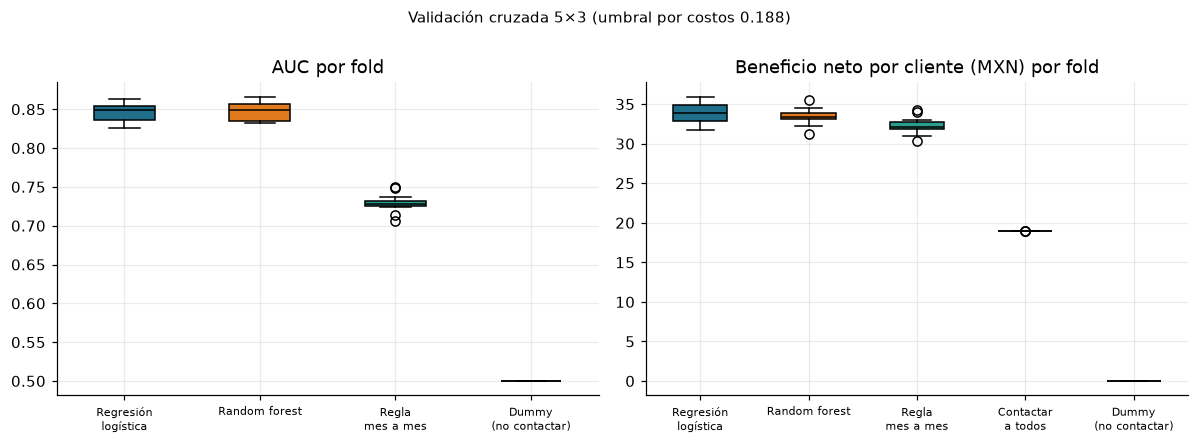

In [12]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
orden = ["Regresión logística", "Random forest", "Regla mes a mes", "Contactar a todos", "Dummy (no contactar)"]
cols = [C_LR, C_RF, C_ALT, C_GRIS, C_BASE]
for ax, col, tit in [(axs[0], "auc", "AUC por fold"), (axs[1], "neto", "Beneficio neto por cliente (MXN) por fold")]:
    data = [serie(o, col) for o in orden if not (col == "auc" and o == "Contactar a todos")]
    labs = [o for o in orden if not (col == "auc" and o == "Contactar a todos")]
    bp = ax.boxplot(data, patch_artist=True, medianprops={"color": "black"})
    ax.set_xticks(range(1, len(labs) + 1), [l.replace(" (", "\n(").replace("Regresión ", "Regresión\n").replace("Regla ", "Regla\n").replace("Contactar ", "Contactar\n") for l in labs])
    for patch, o in zip(bp["boxes"], labs): patch.set_facecolor(cols[orden.index(o)])
    ax.set_title(tit); ax.tick_params(axis="x", labelsize=7.5)
fig.suptitle("Validación cruzada 5×3 (umbral por costos 0.188)", y=1.0, fontsize=10)
fig.tight_layout(); fig.savefig(GRAF / "04_validacion_cruzada.png", dpi=160); plt.show()

## 6. Prueba A/B simulada: campaña de retención (piloto de la Etapa 1 de la Fase I)

**No hay producción real**, así que la prueba A/B se **simula**

----

Supuestos declarados:
- Piloto: 10 % de la base (40,000 clientes), asignados al azar a dos grupos de 20,000 (Etapa 1 de la Fase I)
- Los clientes se generan por **remuestreo** de los clientes del conjunto de prueba, con su probabilidad y su etiqueta real
- Un cliente contactado que sí se iba se retiene con probabilidad **0.17** (aceptación 20 % × atribución 85 %, Excel de la Fase I)
- Cada retención vale 1,440 MXN; cada contacto cuesta 46 MXN
----
- **Experimento 1 (principal, presupuesto igual)** 
  - ambos grupos contactan al 15 %
  - **A** = estrategia actual (regla mes a mes, contactos al azar entre esos clientes)
  - **B** = modelo (top 15 % por probabilidad)
- **Experimento 2 (sin límite de capacidad)** 
  - **A** = contactar a todos los mes a mes
  - **B** = modelo con umbral por costos (0.188)
- Métrica principal
  - proporción de clientes retenidos por la campaña
  - Prueba: **Z de dos proporciones**, bilateral, α = 0.05.

In [13]:
def simular_ab(escenario, n_total=40_000, semilla=SEMILLA, p_score=p_lr):
    rng = np.random.default_rng(semilla)
    idx = rng.integers(0, len(y_te), n_total)
    perm = rng.permutation(n_total); idx = idx[perm]
    mitad = n_total // 2
    out = {}
    for g, sl in [("A", slice(0, mitad)), ("B", slice(mitad, n_total))]:
        ii = idx[sl]; yy = y_te.to_numpy()[ii]; pp = p_score[ii]; rr = regla_te[ii].astype(bool); n = len(ii)
        k = int(np.ceil(CAPACIDAD * n))
        if escenario == 1:
            if g == "A":
                cand = np.flatnonzero(rr); sel = rng.choice(cand, size=min(k, len(cand)), replace=False)
            else:
                sel = np.argsort(-pp)[:k]
        else:
            sel = np.flatnonzero(rr) if g == "A" else np.flatnonzero(pp >= UMBRAL_TEORICO)
        contactado = np.zeros(n, bool); contactado[sel] = True
        retenido = contactado & (yy == 1) & (rng.random(n) < EFECTO)
        neto = retenido * VALOR_CLIENTE - contactado * COSTO_CONTACTO
        out[g] = {"n": n, "contactados": int(contactado.sum()), "retenidos": int(retenido.sum()),
                  "tasa_ret": retenido.mean(), "neto_cliente": neto.mean(), "neto_ser": neto}
    return out

def z_dos_proporciones(x1, n1, x2, n2):
    # Prueba Z de dos proporciones (bilateral), como en el Tema 14, e IC95 de la diferencia (Wald)
    p1, p2 = x1 / n1, x2 / n2
    p_comb = (x1 + x2) / (n1 + n2)
    ee = np.sqrt(p_comb * (1 - p_comb) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / ee
    p_valor = 2 * stats.norm.sf(abs(z))
    ee_ic = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return z, p_valor, (p1 - p2) - 1.96 * ee_ic, (p1 - p2) + 1.96 * ee_ic

def resultado_ab(o):
    cnt = np.array([o["B"]["retenidos"], o["A"]["retenidos"]]); nob = np.array([o["B"]["n"], o["A"]["n"]])
    z, p, lo, hi = z_dos_proporciones(cnt[0], nob[0], cnt[1], nob[1])
    t_neto, p_neto = stats.ttest_ind(o["B"]["neto_ser"], o["A"]["neto_ser"], equal_var=False)
    return {"z": z, "p": p, "dif": o["B"]["tasa_ret"] - o["A"]["tasa_ret"], "ic": (lo, hi),
            "lift_rel": o["B"]["tasa_ret"] / o["A"]["tasa_ret"] - 1,
            "dif_neto": o["B"]["neto_cliente"] - o["A"]["neto_cliente"], "p_neto": p_neto}

filas, detalle = [], {}
for esc, nom in [(1, "Exp. 1: presupuesto igual (15%)"), (2, "Exp. 2: sin límite de capacidad")]:
    o = simular_ab(esc); r = resultado_ab(o); detalle[esc] = (o, r)
    for g, etq in [("A", "A: estrategia actual"), ("B", "B: modelo")]:
        filas.append({"Experimento": nom, "Grupo": etq, "Usuarios": o[g]["n"], "Contactados": o[g]["contactados"],
                      "Retenidos": o[g]["retenidos"], "Tasa de retención": o[g]["tasa_ret"],
                      "Neto/cliente (MXN)": o[g]["neto_cliente"]})
tabla_ab = pd.DataFrame(filas); tabla_ab.to_csv(EVID / "ab_resultados.csv", index=False); display(tabla_ab.round(4))

filas = []
for esc, nom in [(1, "Exp. 1: presupuesto igual"), (2, "Exp. 2: sin límite de capacidad")]:
    r = detalle[esc][1]
    filas.append({"Experimento": nom, "Dif. tasa (B−A)": r["dif"], "IC95 dif.": f"[{r['ic'][0]:.4f}, {r['ic'][1]:.4f}]",
                  "Mejora relativa": r["lift_rel"], "Z": r["z"], "p-valor": r["p"],
                  "Decisión (α=0.05)": "Rechaza H0" if r["p"] < .05 else "No rechaza H0",
                  "Dif. neto/cliente (MXN)": r["dif_neto"], "p neto (Welch)": r["p_neto"]})
tabla_z = pd.DataFrame(filas); tabla_z.to_csv(EVID / "ab_prueba_z.csv", index=False); display(tabla_z.round(4))

,Experimento,Grupo,Usuarios,Contactados,Retenidos,Tasa de retención,Neto/cliente (MXN)
0,Exp. 1: presupuesto igual (15%),A: estrategia actual,20000,3000,208,0.0104,8.0760
1,Exp. 1: presupuesto igual (15%),B: modelo,20000,3000,354,0.0177,18.5880
2,Exp. 2: sin límite de capacidad,A: estrategia actual,20000,11003,803,0.0402,32.5091
3,Exp. 2: sin límite de capacidad,B: modelo,20000,10103,744,0.0372,30.3311


,Experimento,Dif. tasa (B−A),IC95 dif.,Mejora relativa,Z,p-valor,Decisión (α=0.05),Dif. neto/cliente (MXN),p neto (Welch)
0,Exp. 1: presupuesto igual,0.0073,"[0.0050, 0.0096]",0.7019,6.2024,0.000,Rechaza H0,10.512,0.0000
1,Exp. 2: sin límite de capacidad,-0.0030,"[-0.0067, 0.0008]",-0.0735,-1.5299,0.126,No rechaza H0,-2.178,0.4271


In [14]:
# Repetimos la simulación 500 veces para estimar qué tan seguido el A/B detectaría la diferencia (potencia)
pot = {1: [], 2: []}
for s in range(500):
    for esc in (1, 2):
        o = simular_ab(esc, semilla=1000 + s); pot[esc].append(resultado_ab(o))
pot_df = pd.DataFrame({f"Exp. {e}": {"% réplicas con p<0.05": np.mean([r["p"] < .05 for r in pot[e]]) * 100,
                                      "% réplicas con B>A en neto y p<0.05": np.mean([(r["p_neto"] < .05) and (r["dif_neto"] > 0) for r in pot[e]]) * 100,
                                      "Z mediano": np.median([r["z"] for r in pot[e]]),
                                      "Dif. neto/cliente mediana (MXN)": np.median([r["dif_neto"] for r in pot[e]])} for e in (1, 2)})
pot_df.to_csv(EVID / "ab_potencia_500_replicas.csv"); display(pot_df.round(3))

,Exp. 1,Exp. 2
% réplicas con p<0.05,100.000,5.600
% réplicas con B>A en neto y p<0.05,100.000,8.200
Z mediano,6.070,-0.258
Dif. neto/cliente mediana (MXN),10.512,1.193


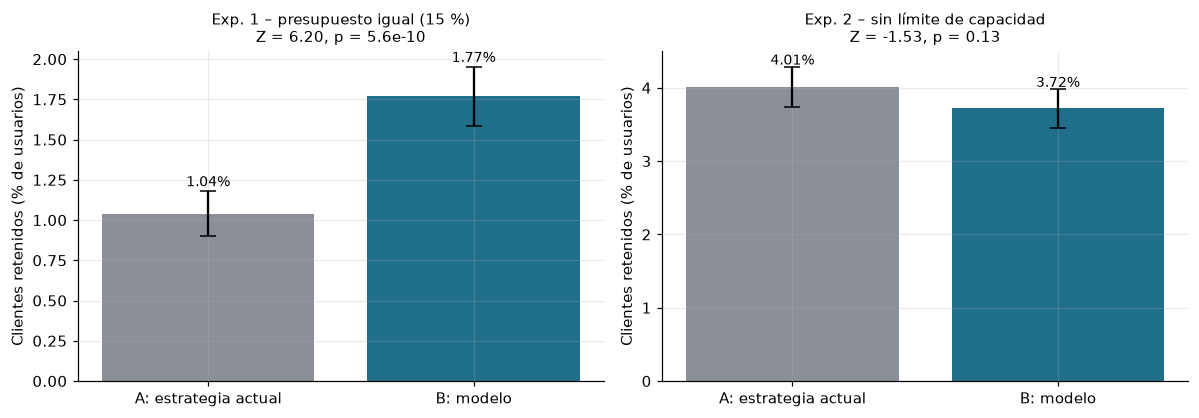

In [15]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, esc, tit in [(axs[0], 1, "Exp. 1 – presupuesto igual (15 %)"), (axs[1], 2, "Exp. 2 – sin límite de capacidad")]:
    o, r = detalle[esc]
    vals = [o["A"]["tasa_ret"] * 100, o["B"]["tasa_ret"] * 100]
    err = [1.96 * np.sqrt(v/100 * (1 - v/100) / o[g]["n"]) * 100 for v, g in zip(vals, ["A", "B"])]
    ax.bar(["A: estrategia actual", "B: modelo"], vals, yerr=err, color=[C_BASE, C_LR], capsize=5)
    for i, v in enumerate(vals): ax.text(i, v + err[i] + .03, f"{v:.2f}%", ha="center", fontsize=9)
    ax.set_title(f"{tit}\nZ = {r['z']:.2f}, p = {r['p']:.2g}", fontsize=9.5); ax.set_ylabel("Clientes retenidos (% de usuarios)")
fig.tight_layout(); fig.savefig(GRAF / "05_prueba_ab.png", dpi=160); plt.show()

## 7. Registro de experimentos en MLflow

In [16]:
import mlflow
mlflow.set_tracking_uri(f"sqlite:///{(RAIZ / 'mlflow.db').as_posix()}")
mlflow.set_experiment("Churn_Telco_Eval_Actividad6")
comunes = {"dataset": "Telco Customer Churn (IBM)", "data_version": "v1.0-datos", "actividad": "Actividad 6",
           "semilla": SEMILLA, "n_train": len(X_tr), "n_test": len(X_te), "c_fp_contacto": COSTO_CONTACTO,
           "c_fn_beneficio": round(BENEFICIO_VP, 2), "umbral_teorico": round(UMBRAL_TEORICO, 4),
           "capacidad": CAPACIDAD, "cv": "RepeatedStratifiedKFold 5x3"}
def a_float(d): return {k: float(v) for k, v in d.items()}

for nom, mod, p_te, extra in [("logistic_regression", lr, p_lr, {"C": 10}),
                              ("random_forest", rf, p_rf, {"n_estimators": 200, "max_depth": 5, "min_samples_leaf": 5})]:
    etq = "Regresión logística" if nom.startswith("log") else "Random forest"
    with mlflow.start_run(run_name=f"A6_{nom}"):
        mlflow.log_params({**comunes, **extra, "umbral_final": round(UMBRAL_TEORICO, 4)})
        mt = metricas(y_te, p_te >= UMBRAL_TEORICO)
        mlflow.log_metrics({"test_roc_auc": auc[etq][0], "test_auc_ic_inf": auc[etq][1], "test_auc_ic_sup": auc[etq][2],
                            "test_recall_umbral_costos": mt["Recall"], "test_precision_umbral_costos": mt["Precisión"],
                            "test_f1_umbral_costos": mt["F1"], "test_neto_cliente_umbral_costos": neto_por_cliente(y_te, p_te >= UMBRAL_TEORICO),
                            "test_neto_cliente_umbral_05": neto_por_cliente(y_te, p_te >= 0.5),
                            "cv_auc_media": res_auc.loc[etq, "media"], "cv_auc_desv": res_auc.loc[etq, "desv"],
                            "cv_neto_cliente_media": res_neto.loc[etq, "media"], "cv_neto_cliente_desv": res_neto.loc[etq, "desv"]})
        for f in ["01_matrices_confusion.png", "02_curva_roc.png", "03_ajuste_umbral.png", "04_validacion_cruzada.png"]:
            mlflow.log_artifact(str(GRAF / f))
        for f in ["comparacion_umbrales_test.csv", "cv_resultados_por_fold.csv", "cv_resumen.csv", "cv_pruebas_significancia.csv"]:
            mlflow.log_artifact(str(EVID / f))
        if nom == "logistic_regression":
            try:
                from mlflow.models import infer_signature
                mlflow.sklearn.log_model(mod, artifact_path="model", signature=infer_signature(X_te, mod.predict_proba(X_te)),
                                         input_example=X_te.head(3), skops_trusted_types=["sklearn.tree._tree.Tree"])
            except Exception as e:
                print("log_model omitido:", type(e).__name__, e)

for nom, p_ in [("regla_mes_a_mes", regla_te.astype(bool)), ("contactar_a_todos", np.ones(len(y_te), bool))]:
    with mlflow.start_run(run_name=f"A6_baseline_{nom}"):
        mlflow.log_params({**comunes, "tipo": "baseline"}); m = metricas(y_te, p_)
        mlflow.log_metrics({"test_recall": m["Recall"], "test_precision": m["Precisión"], "test_f1": m["F1"],
                            "test_neto_cliente": neto_por_cliente(y_te, p_)})

with mlflow.start_run(run_name="A6_prueba_AB_simulada"):
    mlflow.log_params({**comunes, "n_piloto": 40_000, "efecto_retencion": EFECTO, "valor_retencion": VALOR_CLIENTE,
                       "prueba": "Z dos proporciones, bilateral, alpha=0.05"})
    for esc in (1, 2):
        o, r = detalle[esc]
        mlflow.log_metrics({f"exp{esc}_tasa_A": o["A"]["tasa_ret"], f"exp{esc}_tasa_B": o["B"]["tasa_ret"],
                            f"exp{esc}_z": r["z"], f"exp{esc}_p": r["p"], f"exp{esc}_dif_neto_cliente": r["dif_neto"]})
    mlflow.log_artifact(str(GRAF / "05_prueba_ab.png")); mlflow.log_artifact(str(EVID / "ab_resultados.csv"))
    mlflow.log_artifact(str(EVID / "ab_prueba_z.csv")); mlflow.log_artifact(str(EVID / "ab_potencia_500_replicas.csv"))
print("Corridas registradas en MLflow (experimento Churn_Telco_Eval_Actividad6).")

2026/10/31 17:18:33 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/10/31 17:18:33 INFO mlflow.store.db.utils: Updating database tables
2026/10/31 17:18:35 INFO mlflow.tracking.fluent: Experiment with name 'Churn_Telco_Eval_Actividad6' does not exist. Creating a new experiment.
2026/10/31 17:18:36 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Corridas registradas en MLflow (experimento Churn_Telco_Eval_Actividad6).


## 8. Tablero y resumen de decisiones

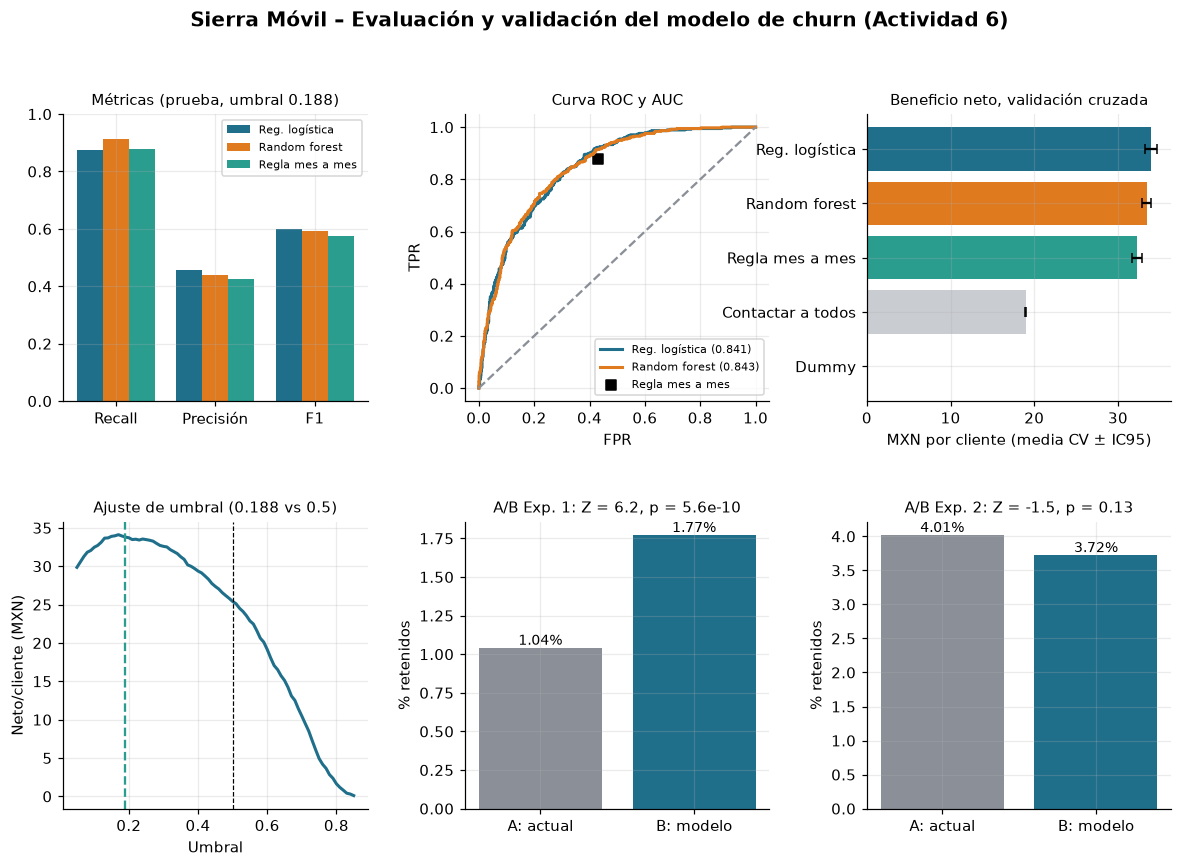

In [17]:
fig = plt.figure(figsize=(13, 8.2)); gs = fig.add_gridspec(2, 3, hspace=.42, wspace=.32)
fig.suptitle("Sierra Móvil – Evaluación y validación del modelo de churn (Actividad 6)", fontsize=13, fontweight="bold", y=.995)
# (a) Métricas por modelo
ax = fig.add_subplot(gs[0, 0])
mets = ["Recall", "Precisión", "F1"]; w = .26
for j, (nom, col) in enumerate([("Reg. logística", C_LR), ("Random forest", C_RF), ("Regla mes a mes", C_ALT)]):
    mm = [metricas(y_te, p_lr >= UMBRAL_TEORICO), metricas(y_te, p_rf >= UMBRAL_TEORICO), m_regla][j]
    ax.bar(np.arange(3) + (j-1)*w, [mm[k] for k in mets], w, color=col, label=nom)
ax.set_xticks(range(3), mets); ax.set_ylim(0, 1); ax.legend(fontsize=7.5); ax.set_title("Métricas (prueba, umbral 0.188)", fontsize=9.5)
# (b) ROC
ax = fig.add_subplot(gs[0, 1])
for nom, sc, col in [("Reg. logística", p_lr, C_LR), ("Random forest", p_rf, C_RF)]:
    f, t, _ = roc_curve(y_te, sc); ax.plot(f, t, color=col, lw=2, label=f"{nom} ({roc_auc_score(y_te, sc):.3f})")
ax.plot([0, 1], [0, 1], "--", color=C_BASE); ax.scatter([f_r], [t_r], marker="s", color="black", label="Regla mes a mes")
ax.set_xlabel("FPR"); ax.set_ylabel("TPR"); ax.legend(fontsize=7.5, loc="lower right"); ax.set_title("Curva ROC y AUC", fontsize=9.5)
# (c) Neto por cliente en CV
ax = fig.add_subplot(gs[0, 2])
ordn = ["Regresión logística", "Random forest", "Regla mes a mes", "Contactar a todos", "Dummy (no contactar)"]
vals = [res_neto.loc[o, "media"] for o in ordn]; errs = [res_neto.loc[o, "media"] - res_neto.loc[o, "IC95 inf"] for o in ordn]
ax.barh(["Reg. logística", "Random forest", "Regla mes a mes", "Contactar a todos", "Dummy"][::-1], vals[::-1], xerr=errs[::-1],
        color=[C_BASE, C_GRIS, C_ALT, C_RF, C_LR], capsize=3)
ax.set_xlabel("MXN por cliente (media CV ± IC95)"); ax.set_title("Beneficio neto, validación cruzada", fontsize=9.5)
# (d) Umbral
ax = fig.add_subplot(gs[1, 0])
ax.plot(bar_lr.umbral, bar_lr.neto_cliente, color=C_LR, lw=2); ax.axvline(0.5, color="black", ls="--", lw=.8)
ax.axvline(UMBRAL_TEORICO, color=C_ALT, ls="--"); ax.set_xlabel("Umbral"); ax.set_ylabel("Neto/cliente (MXN)")
ax.set_title("Ajuste de umbral (0.188 vs 0.5)", fontsize=9.5)
# (e) A/B Exp 1
for k, esc in enumerate((1, 2)):
    ax = fig.add_subplot(gs[1, 1 + k]); o, r = detalle[esc]
    vals = [o["A"]["tasa_ret"] * 100, o["B"]["tasa_ret"] * 100]
    ax.bar(["A: actual", "B: modelo"], vals, color=[C_BASE, C_LR]); ax.set_ylabel("% retenidos")
    for i, v in enumerate(vals): ax.text(i, v, f"{v:.2f}%", ha="center", va="bottom", fontsize=9)
    ax.set_title(f"A/B Exp. {esc}: Z = {r['z']:.1f}, p = {r['p']:.2g}", fontsize=9.5)
fig.savefig(GRAF / "06_tablero_resumen.png", dpi=160, bbox_inches="tight"); plt.show()

In [18]:
mejor = tabla_umbral.loc[f"Costos teórico ({UMBRAL_TEORICO:.3f})"]; base05 = tabla_umbral.loc["0.5 (estándar)"]
print("RESUMEN PARA EL REPORTE")
print(f"- AUC prueba LR: {auc['Regresión logística'][0]:.4f} (IC95 {auc['Regresión logística'][1]:.3f}-{auc['Regresión logística'][2]:.3f}); CV: {res_auc.loc['Regresión logística','media']:.4f} ± {res_auc.loc['Regresión logística','desv']:.4f}")
print(f"- Umbral por costos {UMBRAL_TEORICO:.3f}: recall {mejor['Recall']:.3f}, precisión {mejor['Precisión']:.3f}, neto/cliente {mejor['Neto/cliente (MXN)']:.2f} MXN")
print(f"- Umbral 0.5: recall {base05['Recall']:.3f}, precisión {base05['Precisión']:.3f}, neto/cliente {base05['Neto/cliente (MXN)']:.2f} MXN")
for esc in (1, 2):
    o, r = detalle[esc]; print(f"- A/B exp {esc}: A {o['A']['tasa_ret']:.4%} vs B {o['B']['tasa_ret']:.4%}, Z = {r['z']:.2f}, p = {r['p']:.3g}")

RESUMEN PARA EL REPORTE
- AUC prueba LR: 0.8415 (IC95 0.819-0.862); CV: 0.8464 ± 0.0120
- Umbral por costos 0.188: recall 0.874, precisión 0.457, neto/cliente 33.44 MXN
- Umbral 0.5: recall 0.559, precisión 0.659, neto/cliente 25.96 MXN
- A/B exp 1: A 1.0400% vs B 1.7700%, Z = 6.20, p = 5.56e-10
- A/B exp 2: A 4.0150% vs B 3.7200%, Z = -1.53, p = 0.126
